# Tuần 03 — Thực hành kNN: 4 bài

Demo `01_Demo-kNN.ipynb` dừng ở việc **vote nhãn cho một mẫu test**.

Notebook này có **4 bài**. Mỗi bài là một bộ dữ liệu trên Kaggle. Cả 4 bài đều làm.

Viết hàm kNN một lần ở phần chung (NumPy, không dùng `KNeighborsClassifier`), rồi áp vào từng bài. Điền các ô có `???`. Giữ `np.random.seed(3000)`.

Tải đủ 4 file, đặt vào thư mục `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Iris Species | https://www.kaggle.com/datasets/uciml/iris | `data/Iris.csv` |
| 2 | Palmer Penguins | https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data | `data/penguins_size.csv` |
| 3 | Heart Failure Prediction | https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction | `data/heart.csv` |
| 4 | Mushroom Classification | https://www.kaggle.com/datasets/uciml/mushroom-classification | `data/mushrooms.csv` |


In [1]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder

np.set_printoptions(precision=3, suppress=True)


## Phần chung — hàm kNN

Các bài bên dưới gọi lại 4 hàm này.

**Chuẩn hóa min–max**, min/max tính trên từng cột của `x_train`, rồi áp cùng hai mốc đó cho `x_test`. Cột nào `max == min` thì giữ nguyên.

$$
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

**Khoảng cách Euclid** từ một mẫu test tới mọi dòng train:

$$
d_i = \sqrt{\sum_j (test_j - train_{i,j})^2}
$$

**Một mẫu:** lấy `K` chỉ số gần nhất (`np.argsort`), vote nhãn xuất hiện nhiều nhất. Hòa thì `np.argmax` trên `counts` chọn nhãn có mã nhỏ hơn.

**Cả tập test:** gọi dự đoán từng mẫu, trả về mảng nhãn cùng độ dài `x_test`.


In [3]:
def chuan_hoa_minmax(x_train, x_test):
    x_min = x_train.min(axis=0)
    x_max = x_train.max(axis=0)

    range_x = x_max - x_min
    range_x[range_x == 0] = 1

    x_train_scaled = (x_train - x_min) / range_x
    x_test_scaled = (x_test - x_min) / range_x

    return x_train_scaled, x_test_scaled

def tinh_khoang_cach(test_s, x_train):
   return np.sqrt(np.sum((x_train - test_s) ** 2, axis=1))


def du_doan_1_mau(test_s, x_train, y_train, K):
    distance = tinh_khoang_cach(test_s,x_train)
    index = np.argsort(distance,kind='stable')[:K]
    label , counts = np.unique(y_train[index],return_counts=True)
    return label[np.argmax(counts)]

def du_doan_tap(x_test, x_train, y_train, K):
    return np.array([du_doan_1_mau(t, x_train, y_train, K) for t in x_test])


In [4]:
def chia_train_test(X, Y, ty_le=0.8, seed=3000):
    np.random.seed(seed)
    rand_indices = np.arange(len(Y))
    np.random.shuffle(rand_indices)
    n_train = int(ty_le * len(Y))
    train_idx = rand_indices[:n_train]
    test_idx = rand_indices[n_train:]
    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]


def accuracy(y_pred, y_test):
    return np.mean(y_pred == y_test)


def ve_accuracy_theo_K(x_train, y_train, x_test, y_test, ds_K=None):
    if ds_K is None:
        ds_K = [1, 3, 5, 7, 9, 11, 13, 15]
    ds_acc = [accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test) for K in ds_K]
    print(list(zip(ds_K, np.round(ds_acc, 3))))
    plt.figure(figsize=(6, 4))
    plt.plot(ds_K, ds_acc, marker='o')
    plt.xlabel('K')
    plt.ylabel('accuracy')
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.show()
    return ds_K, ds_acc


---

# Bài 1 — Iris

Nguồn: https://www.kaggle.com/datasets/uciml/iris

File `data/Iris.csv`. 150 bông, 3 loài.

Cột: `Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species`.

- Bỏ cột `Id`. Đó là số thứ tự, không phải số đo của hoa.
- Bốn cột đo là số (cm). Nhãn `Species` là chữ: dùng `LabelEncoder`.
- Chuẩn hóa min–max, rồi so sánh accuracy khi **có** và **không** chuẩn hóa (`K=5`).
- In kiểm tra mẫu test đầu tiên (khoảng cách K láng giềng, nhãn của họ, nhãn đoán, nhãn thật), rồi vẽ accuracy theo K.


In [7]:
raw_iris = np.genfromtxt('data/Iris.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_iris.shape)
print(raw_iris[0])

# TODO: X_iris float (bỏ Id), Y_iris int
X_iris = raw_iris[:,1:5].astype(float)
Y_iris = LabelEncoder().fit_transform(raw_iris[:,5])

print(X_iris.shape, Y_iris.shape)
print(np.unique(Y_iris, return_counts=True))


(150, 6)
['1' '5.1' '3.5' '1.4' '0.2' 'Iris-setosa']
(150, 4) (150,)
(array([0, 1, 2]), array([50, 50, 50]))


K khoảng cách nhỏ nhất: [0.114 0.341 0.349 0.365 0.419]
Nhãn K láng giềng: [2 2 2 2 2]
Nhãn dự đoán: 2
Nhãn thật y_test[0]: 2
accuracy K=5, đã chuẩn hóa: 0.9666666666666667
accuracy K=5, chưa chuẩn hóa: 0.9666666666666667
[(1, np.float64(0.967)), (3, np.float64(0.967)), (5, np.float64(0.967)), (7, np.float64(0.967)), (9, np.float64(0.967)), (11, np.float64(0.967)), (13, np.float64(0.967)), (15, np.float64(0.967))]


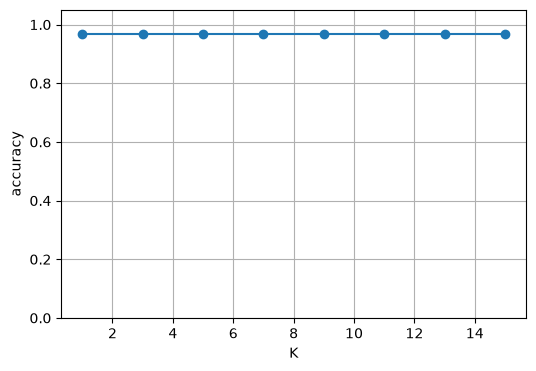

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667),
  np.float64(0.9666666666666667)])

In [8]:
x_train, y_train, x_test, y_test = chia_train_test(X_iris, Y_iris)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

K = 5
# TODO: in K khoảng cách nhỏ nhất, nhãn K láng giềng, nhãn dự đoán, y_test[0]
d = tinh_khoang_cach(x_test_s[0],x_train_s)
index = np.argsort(d,kind='stable')[:K]
print('K khoảng cách nhỏ nhất:', d[index])
print('Nhãn K láng giềng:', y_train[index])
print('Nhãn dự đoán:', du_doan_1_mau(x_test_s[0], x_train_s, y_train, K))
print('Nhãn thật y_test[0]:', y_test[0])

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, K), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 1**

1. `X` có bao nhiêu dòng, bao nhiêu cột? Có bao nhiêu lớp?
2. Accuracy tại `K=5` khi có chuẩn hóa và khi không chuẩn hóa chênh nhau thế nào? Vì sao với Iris mức chênh thường nhỏ?
3. Vì sao không đưa cột `Id` vào feature?


In [10]:
print("Số dòng và cột của X:", X_iris.shape)
print("Số lớp:", len(np.unique(Y_iris)))


Số dòng và cột của X: (150, 4)
Số lớp: 3


In [ ]:
# Bài 1
# 1. Có 150 dòng , 4 cột , 3 lớp
# 2. accuracy tại K=5 khi chuẩn hóa và không chuẩn hóa là như nhau không thay đổi ,
# 3. tại vì Id không có ý nghĩa đến việc dự đoán mà chỉ nên đưa những cột có ảnh hưởng


---

# Bài 2 — Palmer Penguins

Nguồn: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

File `data/penguins_size.csv`. Đoán loài chim cánh cụt.

Cột: `species`, `island`, `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

- Bỏ mọi dòng có ô trống hoặc `NA`.
- Nhãn là `species`.
- `island` và `sex` là chữ: `LabelEncoder` **từng cột**.
- Bốn cột đo là số: `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`.
- Bắt buộc chuẩn hóa. `body_mass_g` khoảng vài nghìn, chiều dài mỏ khoảng vài chục. Không chuẩn hóa thì khoảng cách gần như chỉ còn khối lượng.


In [11]:
raw_pen = np.genfromtxt('data/penguins_size.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng thiếu:', raw_pen.shape)

# TODO: bỏ dòng có '' hoặc 'NA', rồi tạo X_pen (float) và Y_pen (int)
mask = ~np.isin(raw_pen, ['', 'NA']).any(axis=1)
pen = raw_pen[mask]

X_pen = pen[:, 2:6].astype(float)
Y_pen = LabelEncoder().fit_transform(pen[:, 0])
print('sau khi bỏ dòng thiếu:', X_pen.shape, Y_pen.shape)
print(np.unique(Y_pen, return_counts=True))


trước khi bỏ dòng thiếu: (344, 7)
sau khi bỏ dòng thiếu: (334, 4) (334,)
(array([0, 1, 2]), array([146,  68, 120]))


accuracy K=5, đã chuẩn hóa: 0.9850746268656716
accuracy K=5, chưa chuẩn hóa: 0.7910447761194029
[(1, np.float64(0.985)), (3, np.float64(0.985)), (5, np.float64(0.985)), (7, np.float64(0.985)), (9, np.float64(0.985)), (11, np.float64(0.985)), (13, np.float64(0.985)), (15, np.float64(0.985))]


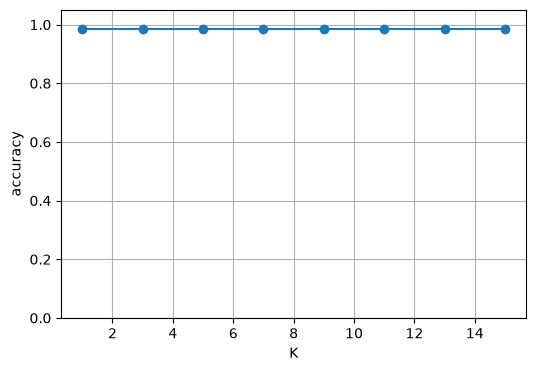

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716),
  np.float64(0.9850746268656716)])

In [12]:
x_train, y_train, x_test, y_test = chia_train_test(X_pen, Y_pen)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 2**

1. Bỏ bao nhiêu dòng vì thiếu dữ liệu?
2. Accuracy `K=5` khi chưa chuẩn hóa thấp hơn bản đã chuẩn hóa ra sao? Cột nào kéo khoảng cách Euclid?
3. `K` nào cho accuracy cao nhất trên đồ thị?


In [ ]:
# Bài 2
# 1. Bỏ 10 dòng vì thiếu dữ liệu
# 2. Chênh lệnh khoảng 0.19 (tức khoảng 19%) , cột `body_mass_g' kéo khoảng cách Euclid
# 3. K lẻ trong khoảng 1 - 15 đều cho cùng 1 kết quả cao nhất (98.5%)


---

# Bài 3 — Heart Failure Prediction

Nguồn: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

File `data/heart.csv`. 918 dòng. Đoán có bệnh tim hay không. Cùng kiểu bài với demo tình trạng xe.

Cột theo đúng thứ tự trong file:

`Age`, `Sex`, `ChestPainType`, `RestingBP`, `Cholesterol`, `FastingBS`, `RestingECG`, `MaxHR`, `ExerciseAngina`, `Oldpeak`, `ST_Slope`, `HeartDisease`.

- Nhãn `HeartDisease` đã là `0` / `1`.
- Cột chữ, `LabelEncoder` từng cột: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`.
- Cột số: `Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`.
- Ghép các cột đã mã hóa thành một ma trận `X` kiểu float, rồi chuẩn hóa min–max.
- Hai lớp, nên các `K` đem thử là số lẻ.


In [15]:
raw_heart = np.genfromtxt('data/heart.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_heart.shape)
print(raw_heart[0])

# TODO: X_heart float, Y_heart int
cols_text = [1, 2, 6, 8, 10]

data = raw_heart.copy()

for col in cols_text:
    data[:, col] = LabelEncoder().fit_transform(data[:, col])

X_heart = np.concatenate([
    data[:, :11].astype(float)
], axis=1)
Y_heart = LabelEncoder().fit_transform(raw_heart[:,11])

print(X_heart.shape, Y_heart.shape)
print(np.unique(Y_heart, return_counts=True))


(918, 12)
['40' 'M' 'ATA' '140' '289' '0' 'Normal' '172' 'N' '0' 'Up' '0']
(918, 11) (918,)
(array([0, 1]), array([410, 508]))


accuracy K=5: 0.875
[(1, np.float64(0.87)), (3, np.float64(0.886)), (5, np.float64(0.875)), (7, np.float64(0.87)), (9, np.float64(0.87)), (11, np.float64(0.864)), (13, np.float64(0.87)), (15, np.float64(0.853))]


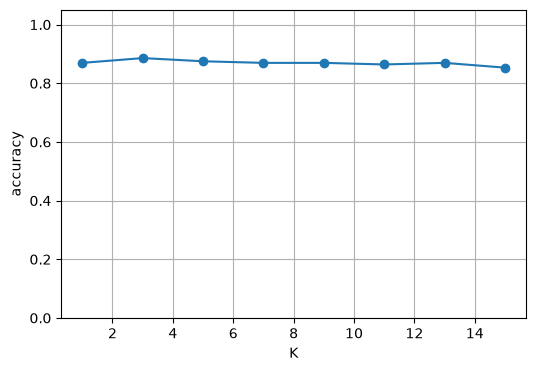

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(0.8695652173913043),
  np.float64(0.8858695652173914),
  np.float64(0.875),
  np.float64(0.8695652173913043),
  np.float64(0.8695652173913043),
  np.float64(0.8641304347826086),
  np.float64(0.8695652173913043),
  np.float64(0.8532608695652174)])

In [16]:
x_train, y_train, x_test, y_test = chia_train_test(X_heart, Y_heart)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 3**

1. Có bao nhiêu người trong tập test? Tỉ lệ lớp `0` và `1` trên toàn bộ dữ liệu là bao nhiêu?
2. Accuracy cao nhất và `K` tương ứng?
3. Vì sao với bài 2 lớp nên chọn `K` lẻ?


In [ ]:
# Số người trong tập test
print("Số người trong tập test:", len(y_test))

# Tỉ lệ lớp 0 và lớp 1 trên toàn bộ dữ liệu
labels, counts = np.unique(Y_heart, return_counts=True)

print("Tỉ lệ từng lớp:")
for label, count in zip(labels, counts):
    print(f"Lớp {label}: {count / len(Y_heart) * 100:.2f}%")

Số người trong tập test: 184
Số lượng từng lớp: {np.int64(0): np.int64(410), np.int64(1): np.int64(508)}
Tỉ lệ từng lớp:
Lớp 0: 44.66%
Lớp 1: 55.34%


In [ ]:
# Bài 3
# 1. Có 184 người trên tập, tỉ lệ 0 và 1 trên toàn bộ dữ liệu lần lượt là : 44.66% và 55.34%
# 2.Accuracy cao nhất là 0.886  và K = 3
# 3. chọn K lẻ để không bị rơi vào tình trạng hòa số phiếu , chỉ có 1 lớp  thắng và chỉ đúng với 2 lớp


---

# Bài 4 — Mushroom Classification

Nguồn: https://www.kaggle.com/datasets/uciml/mushroom-classification

File `data/mushrooms.csv`. Đoán nấm ăn được (`e`) hay độc (`p`).

Mọi cột đều là chữ, cùng kiểu demo xe. Cột 0 là nhãn `class`. Các cột còn lại là feature.

- Bỏ dòng nào còn giá trị `?`.
- `LabelEncoder` **từng cột** feature, rồi mã hóa riêng cột nhãn. Giống đoạn mã hóa trong demo xe.
- **Không** chuẩn hóa min–max. Mã `LabelEncoder` chỉ là tên nhóm được đánh số, không phải số đo cùng đơn vị.
- Tập này vài nghìn dòng. `tinh_khoang_cach` cần tính một lần cho cả `x_train` (vector), không viết vòng `for` từng dòng train.


In [26]:
raw_mush = np.genfromtxt('data/mushrooms.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng có ?:', raw_mush.shape)

# TODO: bỏ dòng chứa '?', X_mush float, Y_mush int
mask = ~np.isin(raw_mush, ['?']).any(axis=1)
mush = raw_mush[mask]

X_mush = mush[:, 1:].copy()

for i in range(X_mush.shape[1]):
    X_mush[:, i] = LabelEncoder().fit_transform(X_mush[:, i])

# Chuyển toàn bộ X sang số thực
X_mush = X_mush.astype(float)

# Mã hóa nhãn
Y_mush = LabelEncoder().fit_transform(mush[:, 0]).astype(int)
print(X_mush.shape, Y_mush.shape)
print(np.unique(Y_mush, return_counts=True))


trước khi bỏ dòng có ?: (8124, 23)
(5644, 22) (5644,)
(array([0, 1]), array([3488, 2156]))


accuracy K=5: 1.0
[(1, np.float64(1.0)), (3, np.float64(1.0)), (5, np.float64(1.0)), (7, np.float64(0.999)), (9, np.float64(0.998)), (11, np.float64(0.998)), (13, np.float64(0.996)), (15, np.float64(0.996))]


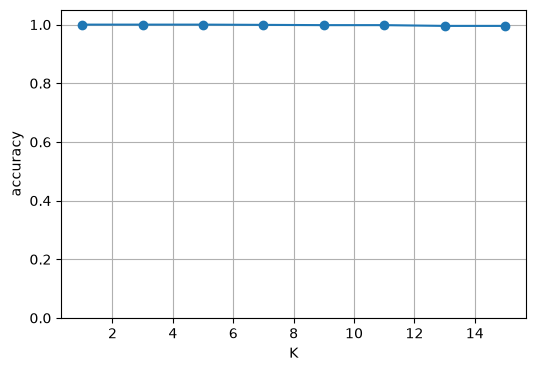

([1, 3, 5, 7, 9, 11, 13, 15],
 [np.float64(1.0),
  np.float64(1.0),
  np.float64(1.0),
  np.float64(0.9991142604074402),
  np.float64(0.9982285208148804),
  np.float64(0.9982285208148804),
  np.float64(0.995571302037201),
  np.float64(0.995571302037201)])

In [27]:
x_train, y_train, x_test, y_test = chia_train_test(X_mush, Y_mush)

# Không gọi chuan_hoa_minmax
print('accuracy K=5:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))
ve_accuracy_theo_K(x_train, y_train, x_test, y_test)


**Nộp kèm bài 4**

1. Còn bao nhiêu dòng sau khi bỏ `?`? Bao nhiêu feature?
2. Accuracy cao nhất và `K` tương ứng?
3. Bài này giống demo tình trạng xe ở bước nào, và khác bài 1–3 ở chỗ nào (chuẩn hóa)?


In [ ]:
# Bài 4
# 1. Có 5644 dòng sau khi bỏ và có 22 feature
# 2. Accuracy cao nhất là 1.0 và K tương ứng là 1,3,5
# 3. Giống: Đọc dữ liệu, Tách X,Y , chia train/test và dùng KNN để đánh giá accuracy theo K
#    Khác : không gọi chuan_hoa_minmax()
     